# 03 · Selección de características: parsimonia, estabilidad y coste

**Objetivo:** estudiar la relación entre número de descriptores, rendimiento predictivo y coste computacional para Ridge, Random Forest, XGBoost y LightGBM.

**Diseño eficiente:** cinco folds sobre `x_train`; en cada fold se calculan MI/correlación una sola vez y cada modelo obtiene un ranking una sola vez. Ese ranking se reutiliza para evaluar todos los valores de `k`. Así se evita repetir la selección completa por cada `k` y por cada fold externo lo que permite ahorrar recursos computacionales.

**Importante:** esta CV sirve para explorar/seleccionar. El `x_test` reservado no se utiliza aquí y debe permanecer intacto hasta la evaluación posterior. Delaney y SC-2 no intervienen en la selección.

La selección y evaluación de características se realiza exclusivamente dentro del conjunto de entrenamiento. El uso de particiones de validación para estimar el rendimiento y evitar decisiones basadas en los datos reservados es coherente con las recomendaciones metodológicas para la evaluación de modelos predictivos (Cawley & Talbot, 2010).

Configuración global cargada
Semilla: 1
RESUMEN DE LOS CONJUNTOS DE DATOS

Entrenamiento (AqSolDB, depurado)
  Moléculas: 6,592
  logS: [-12.06, 1.97]  media=-2.929  sd=2.359

Validación interna (AqSolDB, SD=0)
  Moléculas: 1,316
  logS: [-13.17, 2.14]  media=-2.975  sd=2.411

Validación externa1 (Delaney/ESOL)
  Moléculas: 1,128
  logS: [-11.60, 1.58]  media=-3.050  sd=2.096

Validación externa2 (Tight_SC-2)
  Moléculas: 100
  logS: [-6.79, -1.18]  media=-4.027  sd=1.272

Validación externa3 (Loose_SC-2)
  Moléculas: 32
  logS: [-10.40, -1.24]  media=-5.241  sd=2.176


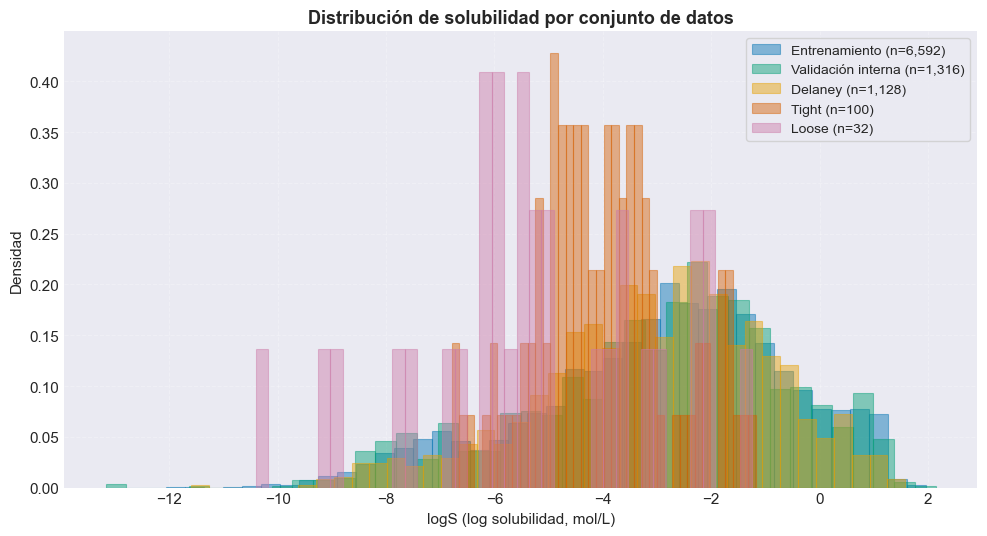

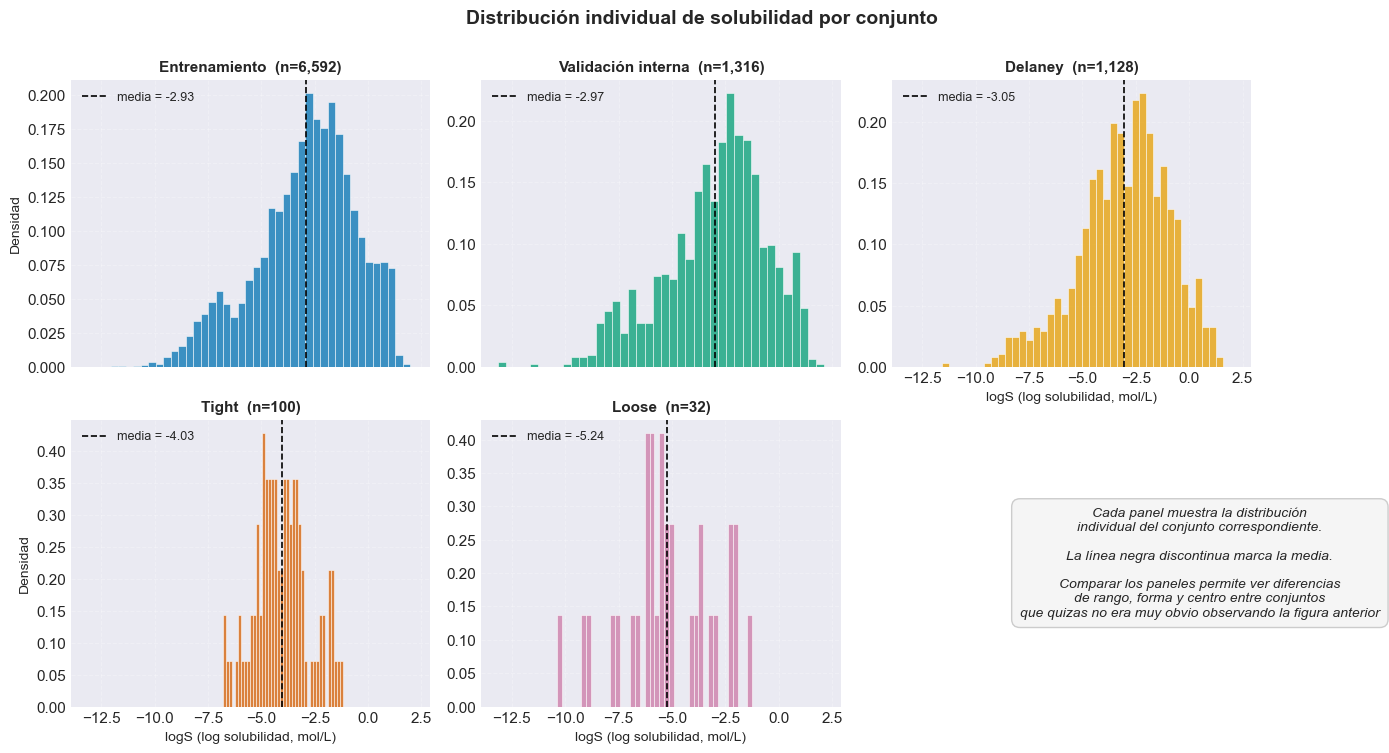

Descriptores candidatos: 124
Entrenamiento: 5273 | prueba reservada sin usar: 1319
CV=5 folds | k=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101] | correlación máxima=0.95


In [10]:
%run 02_configuracion_y_datos.ipynb

import os, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

CRITERIO_CONSENSO = 3
CV_FOLDS = 5
K_VALUES = list(range(1, 102))
CORRELACION_MAX = 0.95

excluir = ['ID','Name','InChI','InChIKey','SMILES','Solubility','SD','Occurrences','Group','Ipc']
columnas_features = [c for c in df_entrenamiento.columns if c not in excluir]
x = df_entrenamiento[columnas_features].copy()
y = df_entrenamiento['Solubility'].copy()
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f'Descriptores candidatos: {len(columnas_features)}')
print(f'Entrenamiento: {len(x_train)} | prueba reservada sin usar: {len(x_test)}')
print(f'CV={CV_FOLDS} folds | k={K_VALUES} | correlación máxima={CORRELACION_MAX}')

## 1. Modelos base

Configuración deliberadamente moderada y de un hilo por modelo para evitar sobrecargar el equipo. La optimización final se realiza en los notebooks posteriores.
Se comparan Ridge, Random Forest, XGBoost y LightGBM, que representan un modelo lineal regularizado y métodos basados en árboles y boosting. Sus fundamentos se describen, respectivamente, en Hoerl y Kennard (1970), Breiman (2001), Chen y Guestrin (2016) y Ke et al. (2017).

In [11]:
def crear_modelos_base(random_state=RANDOM_STATE):
    return {
        'Ridge': Ridge(alpha=1.0),
        'Random Forest': RandomForestRegressor(
            n_estimators=60, max_depth=8, min_samples_split=10,
            min_samples_leaf=5, max_features='sqrt', random_state=random_state, n_jobs=1
        ),
        'XGBoost': XGBRegressor(
            n_estimators=60, max_depth=5, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8, random_state=random_state,
            n_jobs=1, verbosity=0
        ),
        'LightGBM': LGBMRegressor(
            n_estimators=60, max_depth=5, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8, random_state=random_state,
            n_jobs=1, verbosity=-1
        )
    }

## 2. Filtrado MI + correlación, calculado una vez por fold

Se calcula la información mutua en una sola llamada vectorizada. Entre pares con correlación absoluta superior a 0,95 se conserva el descriptor con mayor MI. Todo se ajusta exclusivamente con el subconjunto de entrenamiento del fold.
La información mutua permite estimar la dependencia entre una característica y la variable objetivo, mientras que el filtrado por correlación reduce la redundancia entre descriptores. Estas operaciones se ajustan dentro de cada partición de entrenamiento para evitar utilizar información de su partición de validación.

In [12]:
def filtrar_descriptores(X_fit, y_fit):
    # Una llamada vectorizada, en lugar de una llamada por descriptor.
    mi = mutual_info_regression(X_fit, y_fit, random_state=RANDOM_STATE)
    df_mi = pd.DataFrame({'feature': X_fit.columns, 'mi': mi}).sort_values(
        'mi', ascending=False, kind='mergesort'
    ).reset_index(drop=True)
    candidatos = df_mi.loc[df_mi['mi'] > 0, 'feature'].tolist()
    if not candidatos:
        candidatos = df_mi['feature'].head(min(10, len(df_mi))).tolist()
    if len(candidatos) <= 1:
        return candidatos, df_mi
    corr = X_fit[candidatos].corr().abs()
    mi_dict = df_mi.set_index('feature')['mi'].to_dict()
    descartados = set()
    cols = list(corr.columns)
    for i in range(len(cols)):
        f1 = cols[i]
        if f1 in descartados: continue
        for j in range(i + 1, len(cols)):
            f2 = cols[j]
            if f2 in descartados: continue
            valor = corr.iat[i, j]
            if pd.notna(valor) and valor > CORRELACION_MAX:
                descartados.add(f1 if mi_dict[f1] < mi_dict[f2] else f2)
    return [f for f in candidatos if f not in descartados], df_mi

## 3. Ranking por modelo

Cada ranking se calcula una sola vez por fold. Ridge usa coeficientes absolutos tras estandarizar; los modelos de árboles usan `feature_importances_`. Las importancias se normalizan dentro de cada modelo para facilitar su interpretación, pero no se comparan sus escalas brutas entre algoritmos.

In [13]:
def calcular_importancias(X_fit, y_fit, features_filtradas):
    importancias = {}
    for nombre, modelo in crear_modelos_base().items():
        if nombre == 'Ridge':
            scaler = StandardScaler()
            X_scaled = scaler.fit_transform(X_fit[features_filtradas])
            modelo.fit(X_scaled, y_fit)
            raw = np.abs(np.ravel(modelo.coef_))
        else:
            modelo.fit(X_fit[features_filtradas], y_fit)
            raw = np.asarray(modelo.feature_importances_)
        max_raw = raw.max() if len(raw) else 0
        norm = raw / max_raw if max_raw > 0 else np.zeros_like(raw, dtype=float)
        importancias[nombre] = pd.DataFrame({
            'feature': features_filtradas,
            'importancia': raw,
            'importancia_norm': norm
        }).sort_values('importancia_norm', ascending=False).reset_index(drop=True)
    return importancias


def ajustar_y_predecir(nombre, X_fit, y_fit, X_eval, features):
    modelo = crear_modelos_base()[nombre]
    if nombre == 'Ridge':
        estimador = make_pipeline(StandardScaler(), modelo)
    else:
        estimador = modelo
    estimador.fit(X_fit[features], y_fit)
    return estimador.predict(X_eval[features])

## 4. CV de cinco folds: curvas de rendimiento y estabilidad

En cada fold se filtran los descriptores. Después se evalúan los valores de `k` usando los primeros `k` descriptores del ranking. Esto mantiene la selección independiente del fold de validación y reduce considerablemente los ajustes repetidos.

In [14]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
registros = []
rankings_por_fold = {nombre: [] for nombre in crear_modelos_base().keys()}
mi_por_fold = []

n_fits_estimados = CV_FOLDS * (len(crear_modelos_base()) + len(crear_modelos_base()) * len(K_VALUES))
print(f'Ajustes de modelos estimados en CV: {n_fits_estimados} (sin contar el coste del filtrado MI).')

for fold, (idx_fit, idx_val) in enumerate(cv.split(x_train), start=1):
    t0 = time.time()
    X_fit, y_fit = x_train.iloc[idx_fit], y_train.iloc[idx_fit]
    X_val, y_val = x_train.iloc[idx_val], y_train.iloc[idx_val]
    features_fold, df_mi_fold = filtrar_descriptores(X_fit, y_fit)
    if not features_fold:
        raise RuntimeError(f'El filtro no dejó descriptores en fold {fold}.')
    mi_por_fold.append(df_mi_fold.assign(fold=fold))
    importancias_fold = calcular_importancias(X_fit, y_fit, features_fold)
    for nombre, df_imp in importancias_fold.items():
        ranking = df_imp['feature'].tolist()
        rankings_por_fold[nombre].append(ranking)
        for k in K_VALUES:
            selected = ranking[:min(k, len(ranking))]
            pred = ajustar_y_predecir(nombre, X_fit, y_fit, X_val, selected)
            registros.append({
                'fold': fold, 'modelo': nombre, 'k': k,
                'n_features_real': len(selected),
                'r2': r2_score(y_val, pred),
                'rmse': float(np.sqrt(mean_squared_error(y_val, pred))),
                'mae': float(mean_absolute_error(y_val, pred))
            })
    print(f'Fold {fold}/{CV_FOLDS} completado en {time.time()-t0:.1f} s; '
          f'{len(features_fold)} descriptores tras el filtro.')

df_cv = pd.DataFrame(registros)
df_curvas = (df_cv.groupby(['modelo','k'], as_index=False)
    .agg(r2_cv_media=('r2','mean'), r2_cv_std=('r2','std'),
         rmse_cv_media=('rmse','mean'), rmse_cv_std=('rmse','std'),
         mae_cv_media=('mae','mean'), mae_cv_std=('mae','std'),
         n_features_real_media=('n_features_real','mean')))
print('CV terminada.')

Ajustes de modelos estimados en CV: 2040 (sin contar el coste del filtrado MI).
Fold 1/5 completado en 251.9 s; 103 descriptores tras el filtro.
Fold 2/5 completado en 252.4 s; 101 descriptores tras el filtro.
Fold 3/5 completado en 234.0 s; 104 descriptores tras el filtro.
Fold 4/5 completado en 235.4 s; 102 descriptores tras el filtro.
Fold 5/5 completado en 233.2 s; 103 descriptores tras el filtro.
CV terminada.


## 5. Selección parsimoniosa de `k`

Se aplica la regla de un error estándar: localizar el mayor R² medio y seleccionar el menor `k` cuyo R² medio sea al menos `mejor media − SE` (SE = desviación estándar entre folds / √5). Es una regla práctica de parsimonia, no una prueba formal de equivalencia. Chen, Y., & Yang, Y. (2021). The one standard error rule for model selection: Does it work? *Stats, 4*(4), 868–892. doi:10.3390/stats4040051

In [15]:
curvas_k_por_modelo = {}
k_optimo_por_modelo = {}
estabilidad_features_por_modelo = {}

for nombre in crear_modelos_base().keys():
    curva = df_curvas[df_curvas['modelo'] == nombre].sort_values('k').reset_index(drop=True)
    idx_best = curva['r2_cv_media'].idxmax()
    best_mean = float(curva.loc[idx_best, 'r2_cv_media'])
    best_std = curva.loc[idx_best, 'r2_cv_std']
    se = (float(best_std) / np.sqrt(CV_FOLDS)) if pd.notna(best_std) else 0.0
    umbral = best_mean - se
    candidatos = curva[curva['r2_cv_media'] >= umbral]
    elegido = candidatos.sort_values('k').iloc[0]
    curvas_k_por_modelo[nombre] = curva
    k_optimo_por_modelo[nombre] = {
        'k': int(elegido['k']), 'r2_cv_media': float(elegido['r2_cv_media']),
        'r2_cv_std': float(elegido['r2_cv_std']), 'rmse_cv_media': float(elegido['rmse_cv_media']),
        'mae_cv_media': float(elegido['mae_cv_media']), 'umbral_1se': umbral
    }
    # Estabilidad: frecuencia con que aparece cada descriptor en top-k dentro de folds.
    k_sel = int(elegido['k'])
    all_feats = sorted(set(f for ranking in rankings_por_fold[nombre] for f in ranking))
    estabilidad = pd.DataFrame([{
        'feature': f,
        'frecuencia_folds': sum(f in ranking for ranking in rankings_por_fold[nombre]),
        'frecuencia_topk': sum(f in ranking[:k_sel] for ranking in rankings_por_fold[nombre])
    } for f in all_feats]).sort_values(
        ['frecuencia_topk','frecuencia_folds','feature'], ascending=[False,False,True]
    ).reset_index(drop=True)
    estabilidad_features_por_modelo[nombre] = estabilidad

resumen_k = pd.DataFrame([
    {'modelo': nombre, **vals} for nombre, vals in k_optimo_por_modelo.items()
])
print(resumen_k.round(4).to_string(index=False))

       modelo  k  r2_cv_media  r2_cv_std  rmse_cv_media  mae_cv_media  umbral_1se
        Ridge 31       0.6940     0.0297         1.3087        0.9664      0.6845
Random Forest 26       0.7779     0.0176         1.1157        0.8187      0.7765
      XGBoost 41       0.8261     0.0137         0.9871        0.7110      0.8256
     LightGBM 29       0.8199     0.0147         1.0044        0.7231      0.8192


## 6. Ranking final y conjunto de consenso para los notebooks posteriores

Una vez elegidos los tamaños mediante CV, se vuelve a ajustar el filtrado y los rankings sobre `x_train` completo. Esto es para producir la lista de descriptores que usará el notebook 04; el conjunto de prueba `x_test` sigue sin utilizarse.

In [16]:
features_filtradas, df_mi = filtrar_descriptores(x_train, y_train)
importancias_por_modelo = calcular_importancias(x_train, y_train, features_filtradas)
top_features_por_modelo = {
    nombre: importancias_por_modelo[nombre]['feature'].tolist()[:k_optimo_por_modelo[nombre]['k']]
    for nombre in importancias_por_modelo
}
conteo = Counter(f for feats in top_features_por_modelo.values() for f in feats)
features_comunes_4de4 = sorted(f for f, c in conteo.items() if c == 4)
features_finales = sorted(f for f, c in conteo.items() if c >= CRITERIO_CONSENSO)
if not features_finales:
    # Fallback explícito para evitar que notebook 04 reciba una lista vacía.
    conteo_total = Counter(f for feats in top_features_por_modelo.values() for f in feats)
    features_finales = [f for f, _ in conteo_total.most_common(min(9, len(conteo_total)))]

importancia_promedio = pd.concat([
    importancias_por_modelo[nombre].set_index('feature')['importancia_norm'].rename(nombre)
    for nombre in importancias_por_modelo
], axis=1)
importancia_promedio['promedio'] = importancia_promedio.mean(axis=1, skipna=True)
importancia_promedio = importancia_promedio.sort_values('promedio', ascending=False)

df_comparacion_features = resumen_k.copy()
df_comparacion_features['n_features_consenso'] = len(features_finales)
print('\nDescriptores candidatos:', len(columnas_features))
print(f'Descriptores tras filtro final: {len(features_filtradas)}')
print(f'Consenso >= {CRITERIO_CONSENSO}/4: {len(features_finales)}')
print('Features finales:')
for i, feature in enumerate(features_finales, 1): print(f'{i}. {feature}')


Descriptores candidatos: 124
Descriptores tras filtro final: 101
Consenso >= 3/4: 13
Features finales:
1. AvgIpc
2. BertzCT
3. ExactMolWt
4. FpDensityMorgan1
5. HallKierAlpha
6. MinPartialCharge
7. MolLogP
8. PEOE_VSA6
9. SMR_VSA10
10. SlogP_VSA12
11. SlogP_VSA2
12. TPSA
13. VSA_EState2


## 7. Gráficos de diagnóstico

Las figuras describen los resultados de CV; no consultan los conjuntos externos ni alteran la selección después de verlos.

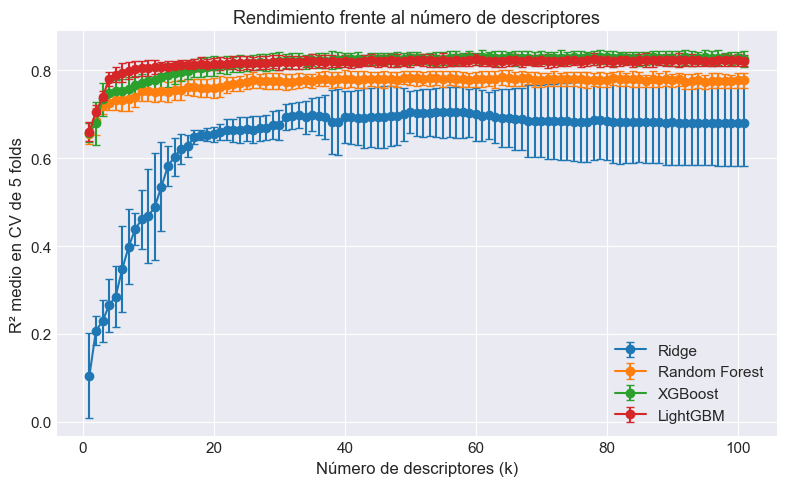

In [17]:
os.makedirs('../resultados/graficos', exist_ok=True)
fig, ax = plt.subplots(figsize=(8,5))
for nombre, curva in curvas_k_por_modelo.items():
    ax.errorbar(curva['k'], curva['r2_cv_media'], yerr=curva['r2_cv_std'], marker='o', capsize=3, label=nombre)
ax.set_xlabel('Número de descriptores (k)')
ax.set_ylabel('R² medio en CV de 5 folds')
ax.set_title('Rendimiento frente al número de descriptores')
ax.legend(); plt.tight_layout()
plt.savefig('../resultados/graficos/01_rendimiento_vs_k_corregido.png', dpi=150)
plt.show()

estab_concat = []
for nombre, tabla in estabilidad_features_por_modelo.items():
    t = tabla.copy(); t['modelo'] = nombre; estab_concat.append(t)
df_estabilidad = pd.concat(estab_concat, ignore_index=True)
df_estabilidad.to_csv('../resultados/features_estabilidad_temporal.csv', index=False)

## 8. Guardar resultados

In [18]:
os.makedirs('../resultados/features', exist_ok=True)
joblib.dump({
    'features_filtradas': features_filtradas,
    'df_mi': df_mi,
    'importancias_por_modelo': importancias_por_modelo,
    'curvas_k_por_modelo': curvas_k_por_modelo,
    'estabilidad_features_por_modelo': estabilidad_features_por_modelo,
    'rankings_por_fold': rankings_por_fold,
    'k_optimo_por_modelo': k_optimo_por_modelo,
    'top_features_por_modelo': top_features_por_modelo,
    'criterio_consenso': CRITERIO_CONSENSO,
    'features_comunes_4de4': features_comunes_4de4,
    'features_finales': features_finales,
    'importancia_promedio': importancia_promedio,
    'df_comparacion_features': df_comparacion_features,
    'df_cv': df_cv,
    'df_curvas': df_curvas,
    'df_estabilidad': df_estabilidad,
    'cv_folds': CV_FOLDS,
    'k_values': K_VALUES
}, '../resultados/features/seleccion_features.pkl')
print('Guardado: ../resultados/features/seleccion_features.pkl')
print('El notebook 04 puede cargar `features_finales` con la misma ruta y clave.')

Guardado: ../resultados/features/seleccion_features.pkl
El notebook 04 puede cargar `features_finales` con la misma ruta y clave.
